# 09 - Fine grid in the low-degradation corner: φ_max, κ_b, d_a

In the standard sweep (notebook 05) the base point sits low on the φ_max axis (base 1, range 0-5) and
on the κ_b axis (base 0.35, range 0-1), because the paper's base values are not in the middle of its
ranges. The corner between zero and the base point is where the endpoints change fastest, but the
standard grid puts only 5 × 8 values there.

This notebook covers that corner with the same number of levels as every other axis:

| Parameter | Fine range | Values | Standard range |
|---|---|---|---|
| φ_max (degradation by living R) | 0 - 1 (up to base) | 21 | 0 - 5 |
| κ_b (degradation by free enzyme) | 0 - 0.35 (up to base) | 21 | 0 - 1 |
| d_a (basal antibiotic decay) | 0 - 0.1 (unchanged) | 21 | 0 - 0.1 |

21 × 21 × 21 = 9,261 runs at the base dose (a0 = 2.15, i = 10); ξ and all other parameters at base.
Engine, endpoints and extinction floor are the same as everywhere else. The base point is the top-right
corner of the φ_max × κ_b plane; the red cross marks it in the base panel (d_a = 0.02). The table is recomputed here if it is missing (about 1.5 minutes).

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from src.analysis.grid_runner import run_fine_corner, fine_axis, FINE_CORNER, BASE_VALUES
from src.analysis.plotting import (heatmap_slices, outcome_map, outcome_counts, marginal_effects,
                                   timecourses, select, label, SHORT, OKABE_ITO)

FORCE_RERUN = False
path = TABLES / "grid_fine_phimax_kappab_da.csv"
if path.exists() and not FORCE_RERUN:
    df = pd.read_csv(path)
else:
    t0 = time.time(); df = run_fine_corner(); df.to_csv(path, index=False, float_format="%.8g")
    print(f"{len(df):,} runs in {time.time() - t0:.0f} s")
PARAMS = list(FINE_CORNER)
settled = df[~df.outcome.isin(["community collapsed", "not converged"])]
print(f"{len(df):,} runs; {len(settled):,} settled")
pd.DataFrame([{"parameter": SHORT[k], "base": BASE_VALUES[k], "min": df[k].min(), "max": df[k].max(),
               "values": df[k].nunique(), "step": round(float(np.diff(np.sort(df[k].unique()))[0]), 4)} for k in PARAMS])

9,261 runs; 9,071 settled


,parameter,base,min,max,values,step
0,φ_max,1.00,0.0,1.00,21,0.0500
1,κ_b,0.35,0.0,0.35,21,0.0175
2,d_a,0.02,0.0,0.10,21,0.0050


## Overview and outcomes

In [2]:
cols = ["f_R_final", "total_final", "peak_loss_S", "peak_loss_R", "t_a_below_1", "t_regain_S", "t_steady_state"]
overview = settled[cols].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
base = select(df, {k: BASE_VALUES[k] for k in PARAMS})
overview["base point"] = base[cols].iloc[0].values
overview.index = [label(c) for c in cols]
print(f"S viable at the end: {df.sensitive_survives.mean():.1%} | needed a horizon beyond 150: {(df.t_end > 150).sum():,} runs "
      f"| strains below one cell in settled runs: R {int(settled.R_extinct_floor.sum())}, S {int(settled.S_extinct_floor.sum())}")
display(overview.round(3))
pd.concat([outcome_counts(df, "outcome").add_prefix("plain model: "),
           outcome_counts(df, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)

S viable at the end: 97.9% | needed a horizon beyond 150: 243 runs | strains below one cell in settled runs: R 0, S 0


,min,median,max,base point
Final resistant fraction f_R,0.061,0.429,0.449,0.433
Final total density,1.998,3.745,4.044,3.832
Peak S loss,0.246,0.428,1.000,0.394
peak_loss_R,0.267,0.462,1.000,0.426
t_a_below_1,4.500,9.000,159.000,8.000
S recovery time (back to start),4.500,9.500,163.000,8.500
Time to steady state,11.000,16.500,177.000,15.500


,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
"S viable, R persists",9071.0,97.95,9071.0,97.95
community collapsed,190.0,2.05,0.0,0.00
community eradicated,0.0,0.00,190.0,2.05


## The φ_max × κ_b plane for four values of basal decay d_a

Blank cells are collapsed runs (the antibiotic is never cleared, so there is no final composition or
recovery time). On the peak-loss map those cells are coloured: the loss there is 100%.

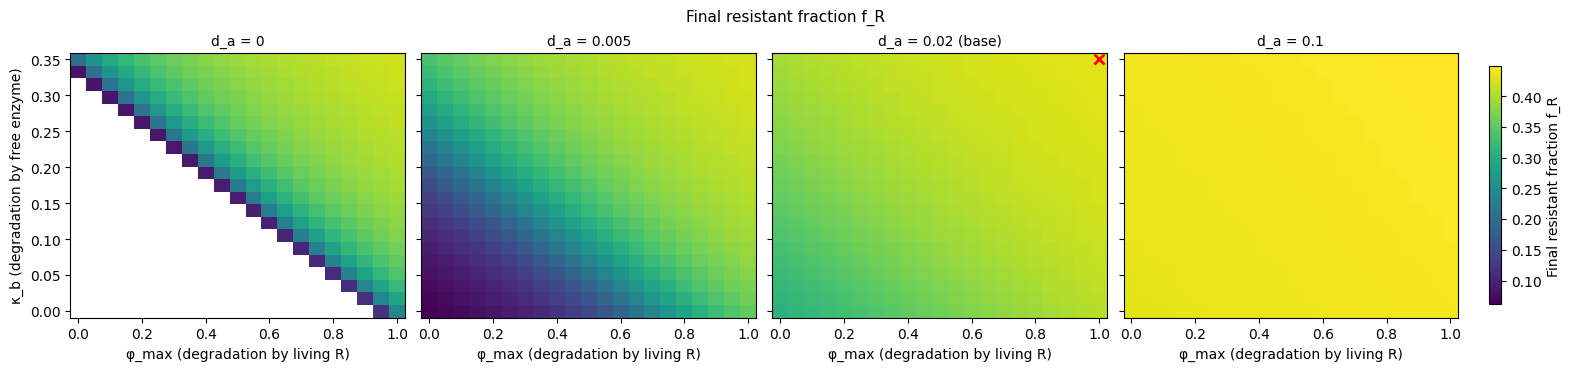

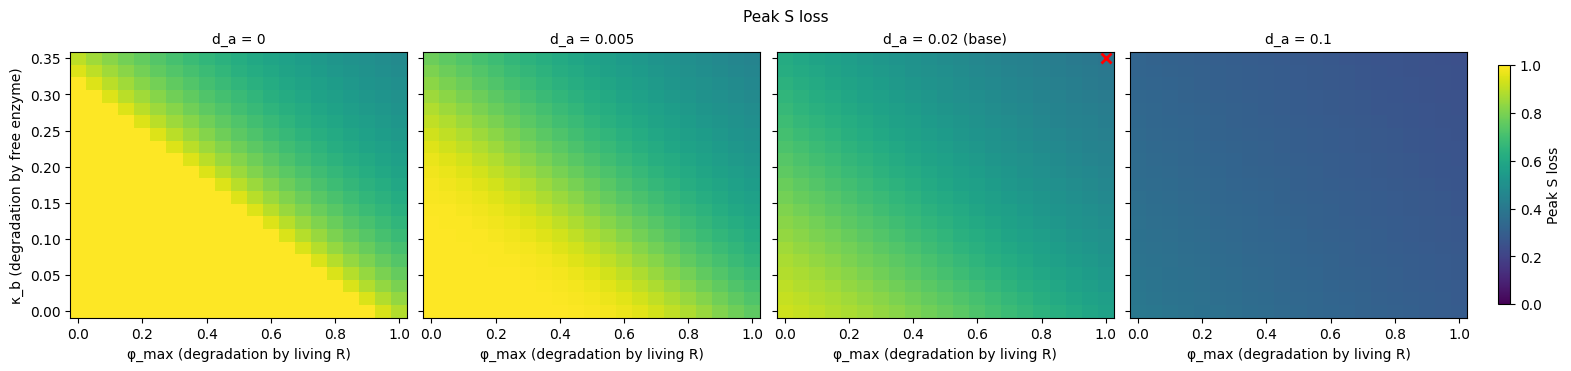

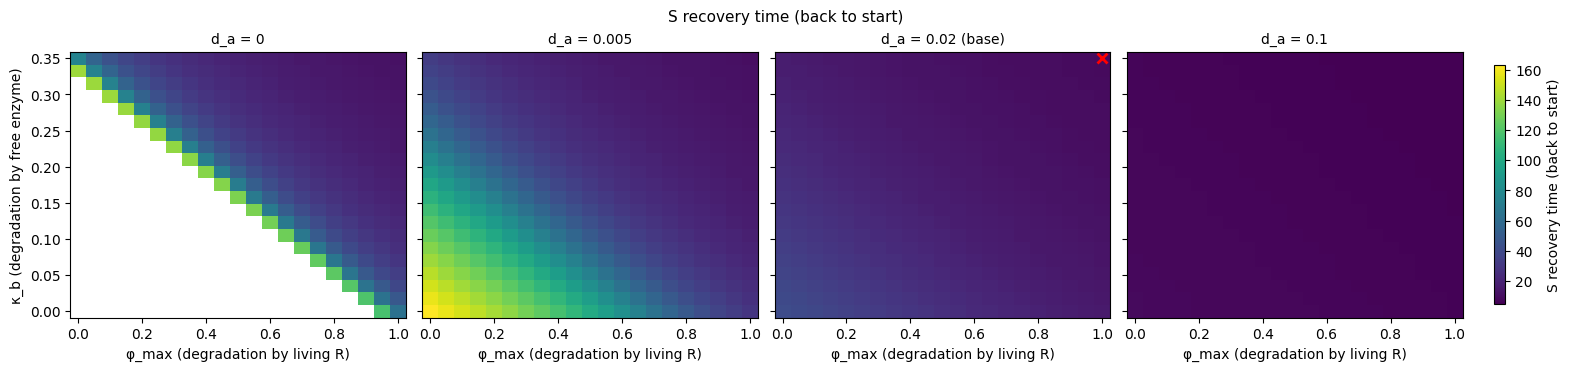

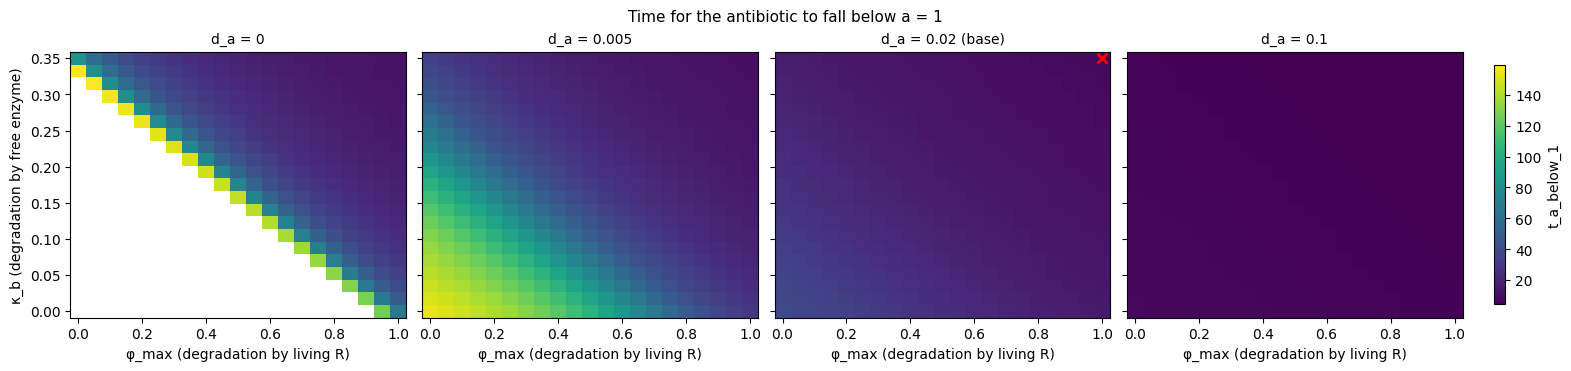

In [3]:
SL = [0.0, 0.005, 0.02, 0.1]
heatmap_slices(df, "phi_max", "kappa_b", "f_R_final", "d_a", SL); plt.show()
heatmap_slices(df, "phi_max", "kappa_b", "peak_loss_S", "d_a", SL, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "phi_max", "kappa_b", "t_regain_S", "d_a", SL); plt.show()
heatmap_slices(df, "phi_max", "kappa_b", "t_a_below_1", "d_a", SL,
               title="Time for the antibiotic to fall below a = 1"); plt.show()

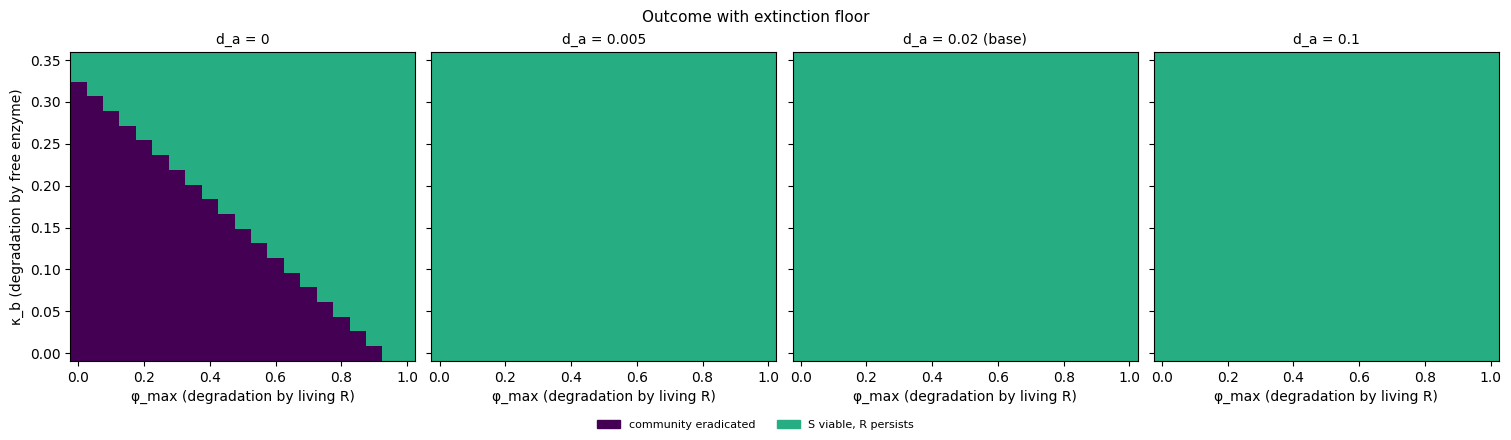

In [4]:
outcome_map(df, "phi_max", "kappa_b", "d_a", SL); plt.show()

## Fine grid vs. the standard grid in the same corner

Same ranges, eleven times as many points per plane.

In [5]:
std = pd.read_csv(TABLES / "grid_kappab_da_phimax_xi.csv.gz")
std = std[np.isclose(std.xi, BASE_VALUES["xi"]) & (std.phi_max <= 1) & (std.kappa_b <= 0.35)]
rows = []
for name, g in [("standard grid, same corner", std), ("fine grid", df)]:
    for da in (0.005, 0.02, 0.1):
        s = g[np.isclose(g.d_a, da) & ~g.outcome.isin(["community collapsed", "not converged"])]
        rows.append({"grid": name, "d_a": da, "points in the φ_max × κ_b plane": len(s),
                     "f_R min": s.f_R_final.min(), "f_R max": s.f_R_final.max(),
                     "peak S loss min": s.peak_loss_S.min(), "peak S loss max": s.peak_loss_S.max(),
                     "longest S recovery": s.t_regain_S.max()})
pd.DataFrame(rows).set_index(["grid", "d_a"]).round(3)

points in the φ_max × κ_b plane  f_R min  f_R max  peak S loss min  peak S loss max  longest S recovery
grid                       d_a                                                                                                           
standard grid, same corner 0.005                               40    0.061    0.424            0.450            1.000               163.0
                           0.020                               40    0.309    0.433            0.394            0.923                41.0
                           0.100                               40    0.432    0.449            0.246            0.402                 8.5
fine grid                  0.005                              441    0.061    0.424            0.450            1.000               163.0
                           0.020                              441    0.309    0.433            0.394            0.923                41.0
                           0.100                              441    0.432    0.449            0.246            0.402                 8.5

## Are the two enzyme routes interchangeable?

Combined enzyme removal u = φ_max + κ_b / 0.35 (each route scaled by its base value, so the base point has u = 2).

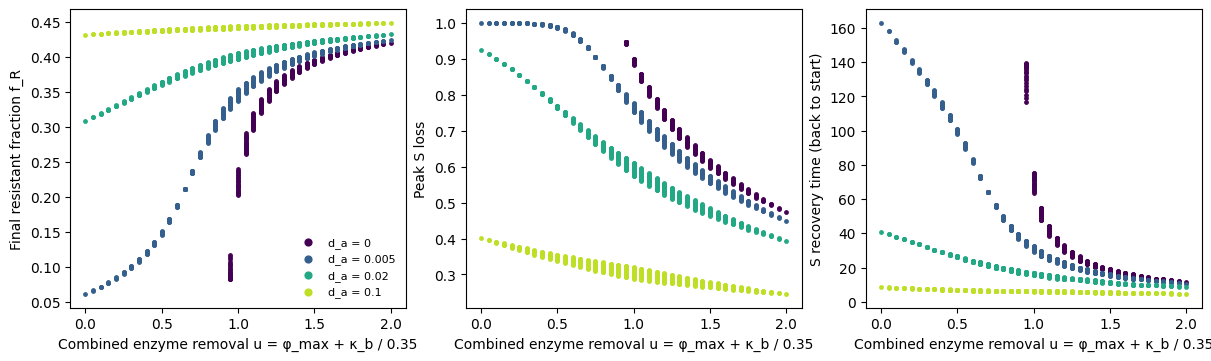

,rank correlation of f_R with u,largest f_R spread at equal u
d_a,,
0.005,0.9983,0.0161
0.020,0.9950,0.0088
0.050,0.9874,0.0052
0.100,0.9758,0.0031


d_a = 0: 190 of 441 runs collapse; largest u that collapses = 0.90, smallest u that survives = 0.95
d_a > 0: 0 collapsed runs


In [6]:
df["u"] = df.phi_max / BASE_VALUES["phi_max"] + df.kappa_b / BASE_VALUES["kappa_b"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
shades = plt.cm.viridis(np.linspace(0.0, 0.9, len(SL)))
for da, col in zip(SL, shades):
    s = df[np.isclose(df.d_a, da) & (df.outcome != "community collapsed")].sort_values("u")
    for ax, y in zip(axes, ["f_R_final", "peak_loss_S", "t_regain_S"]):
        ax.scatter(s.u, s[y], s=6, color=col, label=f"d_a = {da:g}")
for ax, y in zip(axes, ["f_R_final", "peak_loss_S", "t_regain_S"]):
    ax.set_xlabel("Combined enzyme removal u = φ_max + κ_b / 0.35"); ax.set_ylabel(label(y))
axes[0].legend(frameon=False, fontsize=8, markerscale=2)
plt.show()
rows = []
for da in np.sort(df.d_a.unique())[[1, 4, 10, 20]]:
    s = df[np.isclose(df.d_a, da)]
    rows.append({"d_a": da, "rank correlation of f_R with u": s[["u", "f_R_final"]].corr(method="spearman").iloc[0, 1],
                 "largest f_R spread at equal u": s.groupby(s.u.round(6)).f_R_final.agg(lambda v: v.max() - v.min()).max()})
display(pd.DataFrame(rows).set_index("d_a").round(4))
z = df[df.d_a == 0]; coll = z.outcome == "community collapsed"
print(f"d_a = 0: {coll.sum()} of {len(z)} runs collapse; largest u that collapses = {z[coll].u.max():.2f}, smallest u that survives = {z[~coll].u.min():.2f}")
print(f"d_a > 0: {(df[df.d_a > 0].outcome == 'community collapsed').sum()} collapsed runs")

## Effect of each parameter

Blue: median over the rest of the grid, with the 10-90% band. Dashed: the other two parameters at base.

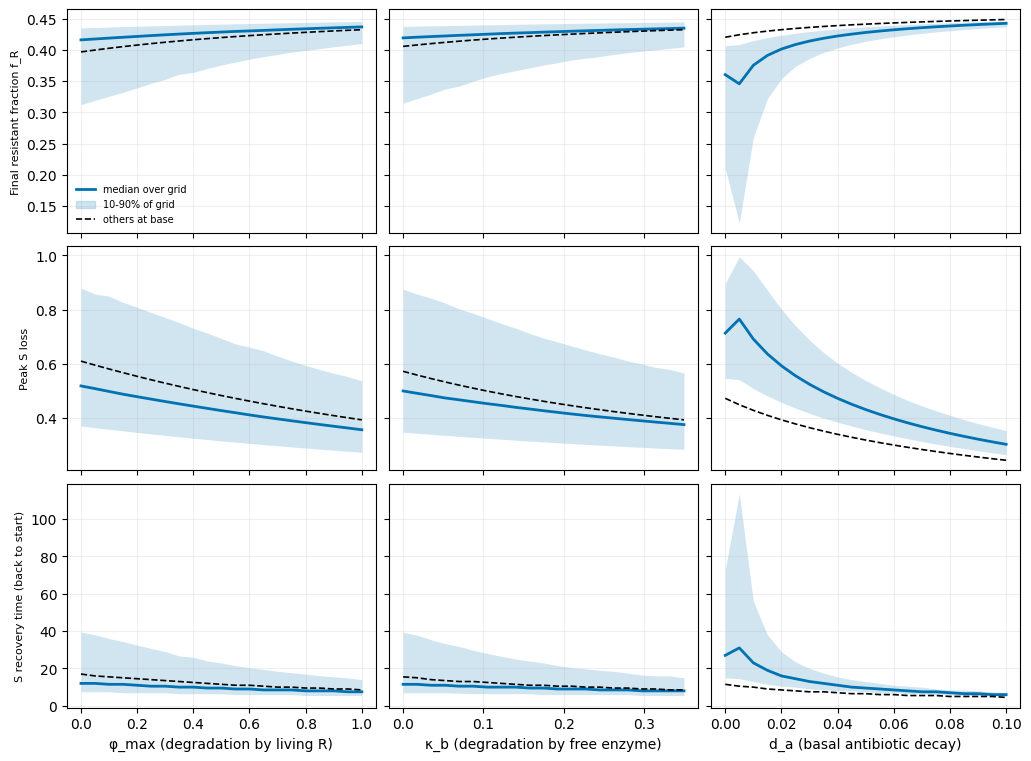

Spearman rank correlation over the fine grid:


,Final resistant fraction f_R,Peak S loss,S recovery time (back to start),Final total density
φ_max,0.35,-0.36,-0.32,0.48
κ_b,0.26,-0.27,-0.26,0.23
d_a,0.88,-0.87,-0.88,0.81


In [7]:
marginal_effects(settled, PARAMS, ["f_R_final", "peak_loss_S", "t_regain_S"]); plt.show()
rho = pd.DataFrame({label(e): [settled[[p, e]].corr(method="spearman").iloc[0, 1] for p in PARAMS]
                    for e in ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]}, index=[SHORT[p] for p in PARAMS])
print("Spearman rank correlation over the fine grid:")
rho.round(2)

## Example time courses

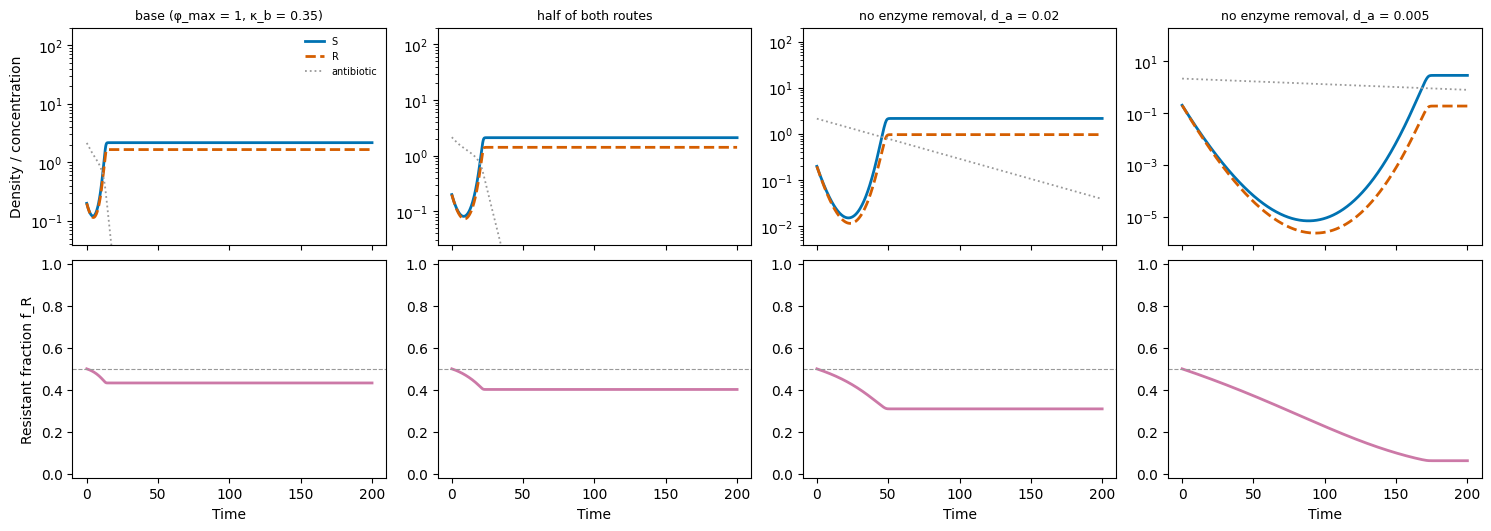

In [8]:
timecourses([("base (φ_max = 1, κ_b = 0.35)", {}),
             ("half of both routes", {"phi_max": 0.5, "kappa_b": 0.175}),
             ("no enzyme removal, d_a = 0.02", {"phi_max": 0.0, "kappa_b": 0.0}),
             ("no enzyme removal, d_a = 0.005", {"phi_max": 0.0, "kappa_b": 0.0, "d_a": 0.005})], t_end=200); plt.show()

## Takeaways

- **The fine grid confirms the standard grid; it adds resolution, not new extremes.** Both grids give
  the same ranges in this corner (f_R 0.06–0.42 at d_a = 0.005, 0.31–0.43 at d_a = 0.02). The fine grid
  resolves each plane with 441 points instead of 40, which is what shows the two results below on
  interchangeable routes and the collapse boundary.
- **Slow antibiotic removal lowers R's share.** At the base traits R is at a net disadvantage whenever
  cells grow: its growth cost (1 − α) exceeds what its protection saves (γ·H(a)·(1 − β)). A longer exposure
  means a deeper crash and more regrowth, and most of R's loss of share accrues during that regrowth.
  The price is a deeper and longer crash for both strains (S recovery time up to 163).
- **The corner only matters when basal decay is slow.** At d_a = 0.1 the plane is flat
  (f_R 0.43–0.45, peak S loss 25–40%); at d_a = 0.005 it spans f_R 0.06–0.42 and peak S loss 45–100%. Over the whole fine grid d_a has the strongest rank
  correlation with every endpoint (0.88 with f_R).
- **The two enzyme routes are nearly interchangeable.** For d_a > 0, final f_R is almost a function of
  the single combined quantity u = φ_max + κ_b / 0.35 (rank correlation 0.976–0.998; runs with equal u
  differ in f_R by at most 0.016): going from κ_b = 0 to 0.35 does the same as going from φ_max = 0 to 1.
  The match is looser at d_a = 0, close to the collapse boundary (spread up to 0.04).
- **Collapse has a sharp boundary.** With no basal decay (d_a = 0) the community collapses when u ≤ 0.90
  and survives when u ≥ 0.95 (190 of 441 runs collapse). With any d_a > 0 on this grid no run collapses.
- **No run meets the goal.** Neither strain falls below one cell in any run that settles, so slower
  drug removal at the base dose lowers R's share but does not remove R.

**Limits.** ξ is fixed at its base value (0.8). The dose is the base dose only. The combined quantity u is
an empirical summary of this grid, not a derived result.